In [1]:
# -----------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
from scipy import stats
from scipy.stats import boxcox
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm, skew, spearmanr, qmc
from scipy.optimize import minimize
from sklearn.model_selection import LeaveOneOut
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)
SK_RANDOM_STATE = np.random.RandomState(SEED)  # sklearn wants a RandomState

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# ---------------------------------------------------------------- 
# Figures settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



n = 30 (20 initial + 10 queried); newest x = [1. 1. 1. 1.], y = 8662.4825
best observed: row 29, x = [1. 1. 1. 1.], y = 8662.4825
skew raw 1.88, skew log -0.50, Box-Cox lambda 0.067




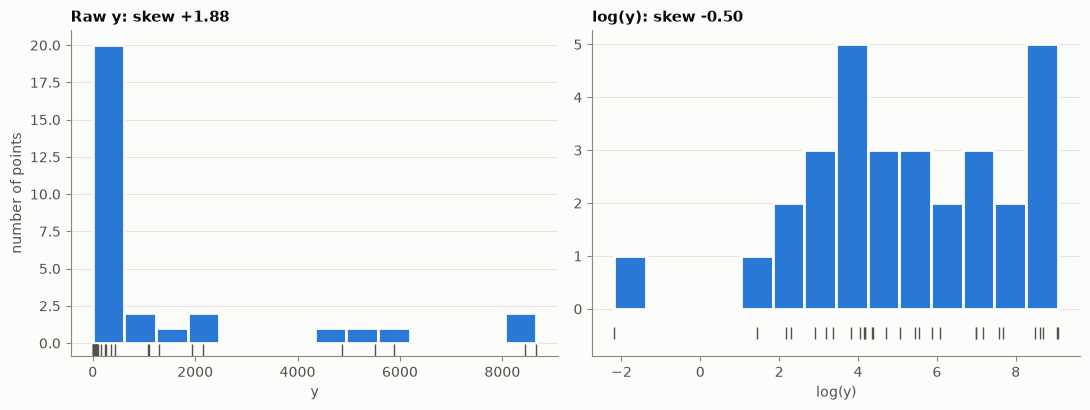

In [2]:
# -----------------------------------------------------------------------
# 1. Data
# -----------------------------------------------------------------------
X = np.load('..\Function_5_Data\Week_11_Data/F5_Week_11_inputs.npy')
y = np.load('..\Function_5_Data\Week_11_Data/F5_Week_11_outputs.npy')

n, d = X.shape
N_INITIAL = 20
best = int(np.argmax(y))
CORNER = np.ones(d)
print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried); newest x = {np.round(X[-1], 6)}, y = {y[-1]:.4f}")
print(f"best observed: row {best}, x = {np.round(X[best], 6)}, y = {y[best]:.4f}")
print(f"skew raw {skew(y):.2f}, skew log {skew(np.log(y)):.2f}, Box-Cox lambda {boxcox(y)[1]:.3f}")
print('\n')

# Fig 1: target distribution
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (title, v, xl) in zip(axes, [("Raw y", y, "y"), ("log(y)", np.log(y), "log(y)")]):
    ax.hist(v, bins=14, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.plot(v, np.full(n, -0.45), "|", color=INK2, markersize=9, clip_on=False)
    ax.set_title(f"{title}: skew {skew(v):+.2f}"); ax.set_xlabel(xl)
    ax.set_ylim(bottom=-0.9); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("number of points")
fig.tight_layout()


MODELS (LOO with hyperparameters fixed; errors in raw y)
  log-iso  ls=[0.522]  own-scale LOO RMSE/std=0.611  Spearman=0.809  raw RMSE all=724  raw RMSE top 6=1521
  log-ARD  ls=[3.408 0.178 0.729 0.647]  own-scale LOO RMSE/std=0.586  Spearman=0.852  raw RMSE all=662  raw RMSE top 6=1423
  raw-iso  ls=[1.979]  own-scale LOO RMSE/std=0.120  Spearman=0.819  raw RMSE all=298  raw RMSE top 6=409
  raw-ARD  ls=[1.949 4.614 1.765 1.791]  own-scale LOO RMSE/std=0.097  Spearman=0.838  raw RMSE all=243  raw RMSE top 6=136


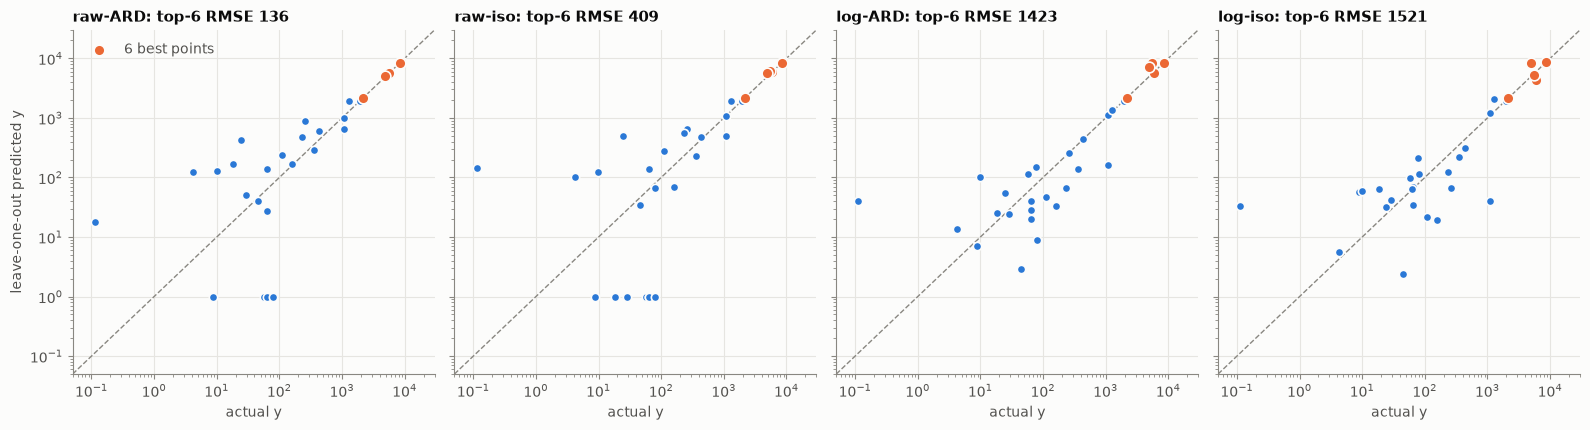

In [3]:
# ---------------------------------------------------------------- 
# Models and LOO CV
# ---------------------------------------------------------------- 
def fit(t, ard):
    k = (ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=np.ones(d) if ard else 1.0,
                                      length_scale_bounds=(1e-2, 1e2), nu=2.5)
         + WhiteKernel(1e-4, (1e-8, 1e-1)))
    return GaussianProcessRegressor(kernel=k, normalize_y=True, alpha=1e-10,
                                    n_restarts_optimizer=20, random_state=SEED).fit(X, t)

TARGETS = {"log": (np.log(y), np.exp), "raw": (y.copy(), lambda m: m)}
models, loos = {}, {}
top = np.argsort(-y)[:6]
print("\nMODELS (LOO with hyperparameters fixed; errors in raw y)")
for tname, (t, back) in TARGETS.items():
    for ard in (False, True):
        key = f"{tname}-{'ARD' if ard else 'iso'}"
        gp = fit(t, ard)
        mu = np.empty(n)
        for i in range(n):
            keep = np.arange(n) != i
            g = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None, normalize_y=True,
                                         alpha=1e-10).fit(X[keep], t[keep])
            mu[i] = g.predict(X[i:i + 1])[0]
        yb = back(mu)
        models[key], loos[key] = gp, yb
        ls = np.atleast_1d(gp.kernel_.k1.k2.length_scale)
        print(f"  {key:8s} ls={np.round(ls, 3)}  own-scale LOO RMSE/std={np.sqrt(np.mean((t - mu) ** 2)) / t.std():.3f}  "
              f"Spearman={spearmanr(y, yb)[0]:.3f}  raw RMSE all={np.sqrt(np.mean((y - yb) ** 2)):.0f}  "
              f"raw RMSE top 6={np.sqrt(np.mean((y[top] - yb[top]) ** 2)):.0f}")

def predict(key, Z):
    m, s = models[key].predict(np.atleast_2d(Z), return_std=True)
    return (np.exp(m), s) if key.startswith("log") else (m, s)

def p_improve(key, Z):
    m, s = models[key].predict(np.atleast_2d(Z), return_std=True)
    thr = np.log(y.max()) if key.startswith("log") else y.max()
    return norm.sf((thr - m) / np.maximum(s, 1e-12))


KEYS = ["raw-ARD", "raw-iso", "log-ARD", "log-iso"]
# Fig 2: LOO predicted vs actual, raw y, log axes
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), sharey=True)
for ax, key in zip(axes, KEYS):
    yb = np.maximum(loos[key], 1)
    lim = [5e-2, 3e4]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.scatter(y, yb, s=36, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.scatter(y[top], yb[top], s=60, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=4, label="6 best points")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{key}: top-6 RMSE {np.sqrt(np.mean((y[top] - loos[key][top]) ** 2)):.0f}")
    ax.set_xlabel("actual y")
axes[0].set_ylabel("leave-one-out predicted y")
axes[0].legend(frameon=False, loc="upper left", labelcolor=INK2)
fig.tight_layout()


CANDIDATES: predicted y (P(observation > current best))
  A: corner again (1, 1, 1, 1)           x = (1.000000, 1.000000, 1.000000, 1.000000)  raw-ARD=8632 (0.221)  raw-iso=8631 (0.204)  log-ARD=8639 (0.288)  log-iso=8662 (0.499)
  B: UCB, week-10 script                 x = (1.000000, 1.000000, 1.000000, 0.972609)  raw-ARD=8267 (0.000)  raw-iso=8275 (0.000)  log-ARD=8447 (0.372)  log-iso=8625 (0.484)
  C: log-ARD highest P(improve)          x = (1.000000, 0.994177, 1.000000, 1.000000)  raw-ARD=8613 (0.107)  raw-iso=8590 (0.040)  log-ARD=8740 (0.536)  log-iso=8582 (0.404)
  D: EI, week-10 script (trust region)   x = (1.000000, 0.750000, 1.000000, 1.000000)  raw-ARD=7830 (0.001)  raw-iso=6912 (0.000)  log-ARD=1584 (0.093)  log-iso=3714 (0.269)
  E: opposite x2 corner (1, 0, 1, 1)     x = (1.000000, 0.000000, 1.000000, 1.000000)  raw-ARD=6101 (0.004)  raw-iso=3380 (0.000)  log-ARD=177 (0.047)  log-iso=443 (0.096)




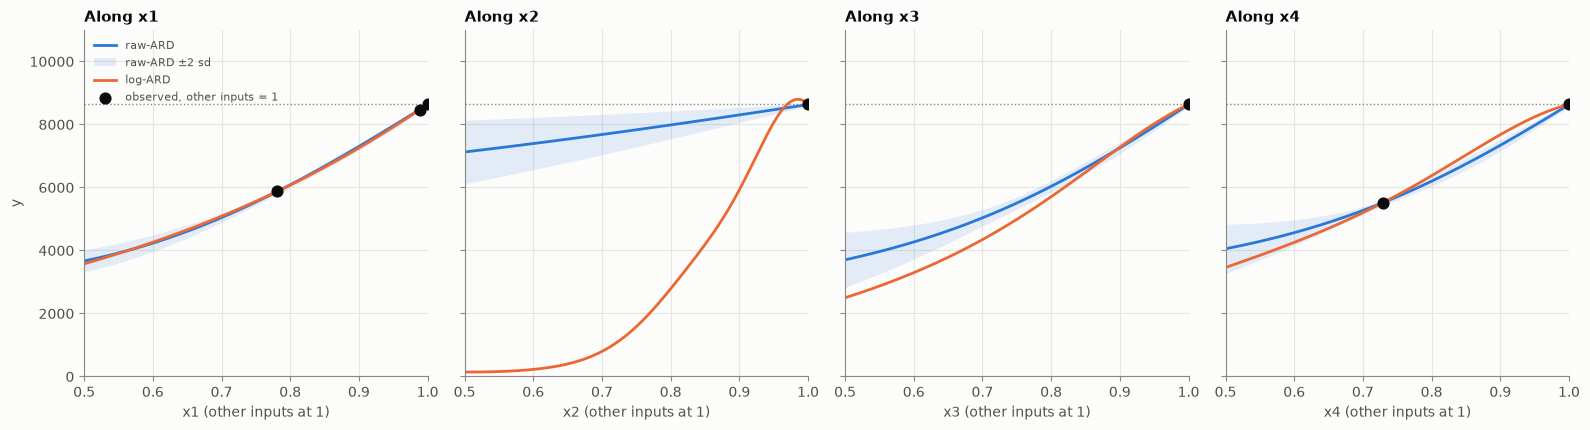

In [4]:
# ---------------------------------------------------------------- 
# Candidates
# ---------------------------------------------------------------- 
S = np.vstack([qmc.Sobol(d, seed=1).random(2 ** 15), np.array(np.meshgrid(*[[0, 1]] * d)).reshape(d, -1).T])
def argmax(fn):
    v = fn(S); x0 = S[v.argmax()]
    r = minimize(lambda q: -fn(q[None])[0], x0, bounds=[(0, 1)] * d, method="L-BFGS-B")
    return r.x if -r.fun >= v.max() else x0

cands = {
    "A: corner again (1, 1, 1, 1)": CORNER,
    "B: UCB, week-10 script": np.array([1.0, 1.0, 1.0, 0.972609]),
    "C: log-ARD highest P(improve)": argmax(lambda Z: p_improve("log-ARD", Z)),
    "D: EI, week-10 script (trust region)": np.array([1.0, 0.75, 1.0, 1.0]),
    "E: opposite x2 corner (1, 0, 1, 1)": np.array([1.0, 0.0, 1.0, 1.0]),
}
KEYS = ["raw-ARD", "raw-iso", "log-ARD", "log-iso"]
print("\nCANDIDATES: predicted y (P(observation > current best))")
for name, xc in cands.items():
    parts = [f"{k}={predict(k, xc)[0][0]:.0f} ({p_improve(k, xc)[0]:.3f})" for k in KEYS]
    print(f"  {name:38s} x = ({', '.join(f'{v:.6f}' for v in xc)})  " + "  ".join(parts))

print('\n')
# Fig 3: slices through the corner along each input
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), sharey=True)
xs = np.linspace(0.5, 1.0, 200)
for j, ax in enumerate(axes):
    Z = np.tile(CORNER, (len(xs), 1)); Z[:, j] = xs
    for key, col in [("raw-ARD", BLUE), ("log-ARD", ORANGE)]:
        m, s = predict(key, Z)
        ax.plot(xs, m, color=col, lw=2, label=key)
        if key == "raw-ARD":
            ax.fill_between(xs, m - 2 * s, m + 2 * s, color=col, alpha=0.12, lw=0, label="raw-ARD ±2 sd")
    others = [k for k in range(d) if k != j]
    on_line = np.all(np.isclose(X[:, others], 1.0), axis=1)
    ax.scatter(X[on_line, j], y[on_line], s=60, color=INK, zorder=4, label="observed, other inputs = 1")
    ax.axhline(y.max(), color=MUTED, lw=1, ls=":")
    ax.set_xlabel(f"x{j + 1} (other inputs at 1)"); ax.set_title(f"Along x{j + 1}")
    ax.set_xlim(0.5, 1.0); ax.set_ylim(0, 11000)
axes[0].set_ylabel("y")
axes[0].legend(frameon=False, loc="upper left", fontsize=8, labelcolor=INK2)
fig.tight_layout()


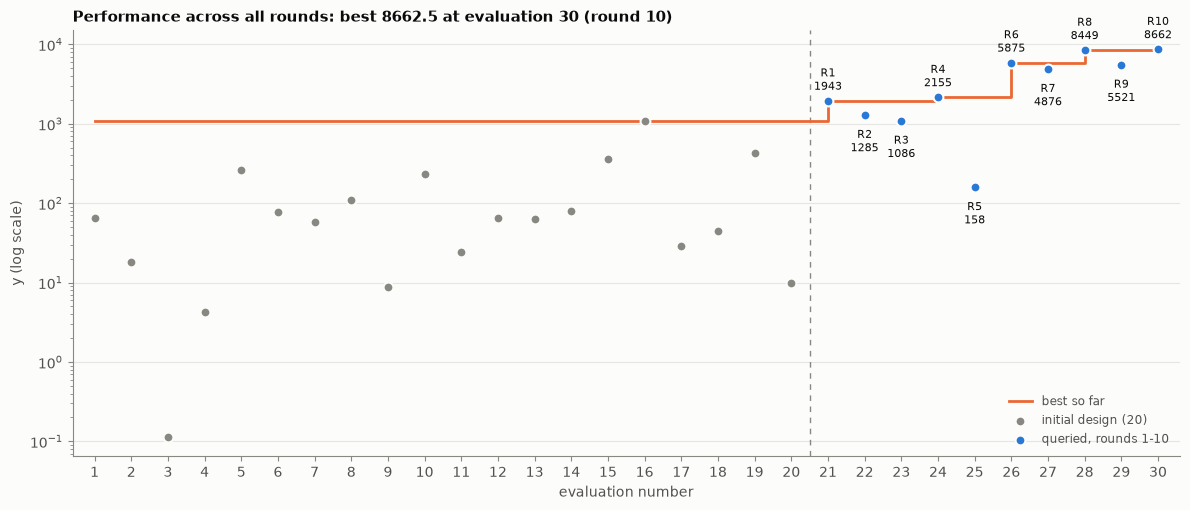

In [5]:
# Fig 4: performance across all rounds
idx = np.arange(1, n + 1)
bsf = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, bsf, where="post", color=ORANGE, lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=50, color=MUTED, edgecolor=SURFACE, linewidth=1.5, label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:], y[N_INITIAL:], s=50, color=BLUE, edgecolor=SURFACE, linewidth=1.5, label=f"queried, rounds 1-{n - N_INITIAL}", zorder=3)
for i in range(N_INITIAL, n):
    ax.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.0f}", (idx[i], y[i]), xytext=(0, 8 if y[i] >= bsf[i] else -26),
                textcoords="offset points", ha="center", fontsize=8, color=INK)
ax.set_yscale("log"); ax.set_xticks(idx); ax.set_xlim(0.4, n + 0.6)
ax.grid(axis="x", visible=False); ax.set_xlabel("evaluation number"); ax.set_ylabel("y (log scale)")
ax.set_title(f"Performance across all rounds: best {y.max():.1f} at evaluation {best + 1} (round {best - N_INITIAL + 1})")
ax.legend(frameon=False, loc="lower right", fontsize=8.5, labelcolor=INK2)
fig.tight_layout()